<h1 align = "Center">
Lotus Group Customer Behavior Analysis

<h2 align = "Center">
Exploratory Data Analysis — Customer Behaviour
</h1>

Now we understand the business.

Our objective is not simply to produce charts. We want to discover patterns that can help Lotus Group:

1. Understand how frequently customers purchase.
2. Identify high-value and low-value customers.
3. Understand customer spending behaviour.
4. Identify preferred product categories.
5. Investigate purchasing trends over time.
6. Identify behavioural patterns that may help predict future purchases and spending.

We want to approach these questions systematically.

In [1]:
import pandas as pd
from pathlib import Path

# Define path to folder
data_path = Path(r"../01_data/processed")

def load_csv (filename):
    return pd.read_csv(data_path/filename)

# Establishing the Overall Purchasing Picture

In [2]:
# load data for EDA
transaction = load_csv("transaction_data.csv")
orders = load_csv("orders_clean.csv")

# Overall purchasing overview

print("Unique Customers:", transaction["customer_id"].nunique())

print("Unique Orders:", transaction["order_id"].nunique())

print("Transaction Lines:", transaction["detail_id"].nunique())

print("Total Quantity Sold:", transaction["quantity"].sum())

print("Total Recorded Order Revenue:",
      orders["total_revenue"].sum())

print("Total Completed Order Revenue:",
      orders.loc[
          orders["order_status"] == "Completed",
          "total_revenue"
      ].sum())

print("Completed Orders:",
      (orders["order_status"] == "Completed").sum())

print("Returned Orders:",
      (orders["order_status"] == "Returned").sum())

print("Cancelled Orders:",
      (orders["order_status"] == "Cancelled").sum())

Unique Customers: 2945
Unique Orders: 12000
Transaction Lines: 25099
Total Quantity Sold: 43313
Total Recorded Order Revenue: 45350979.0
Total Completed Order Revenue: 39652714.0
Completed Orders: 10442
Returned Orders: 1063
Cancelled Orders: 495


These figures establish the baseline against which we'll interpret subsequent findings.

### Observations:

**Customer activity**: *2,945* of the *3,000* registered customers made at least one recorded purchase. The remaining *55* have no recorded orders.

**Transaction volume**: The *12,000* orders generated *25,099* product lines. This means an order can contain multiple products.

**Order outcomes**: Approximately *87%* of orders were completed, *8.9%* returned and *4.1%* cancelled.

**Revenue**: *EGP 39.65 million* is the revenue associated with completed orders. We'll use this as our initial revenue measure for customer spending analysis.

**Caution**: these are three-year aggregate figures. They tell us the scale of the business, but not whether individual customers are becoming more or less valuable over time.

## Understanding Customer Purchasing Frequency

This is our first proper customer-level investigation.

We want to establish:
- How many orders does a typical customer place?
- What proportion of customers are one-time buyers?
- How many customers make repeat purchases?
- Are purchases concentrated among a small group of customers?

Here, only completed orders count as purchases.

In [3]:
# Retain completed orders only
completed_orders = orders[
    orders["order_status"] == "Completed"
].copy()

# Calculate orders per customer
customer_frequency = (
    completed_orders
    .groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Summarize purchasing frequency
print("Customer Purchasing Frequency")
print(customer_frequency["total_orders"].describe())

print("\nCustomers by Number of Orders")
print(customer_frequency["total_orders"].value_counts().sort_index())

print("\nOne-Time Customers:",
      (customer_frequency["total_orders"] == 1).sum())

print("Repeat Customers:",
      (customer_frequency["total_orders"] > 1).sum())

Customer Purchasing Frequency
count    2905.000000
mean        3.594492
std         1.736648
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        11.000000
Name: total_orders, dtype: float64

Customers by Number of Orders
total_orders
1     304
2     543
3     654
4     601
5     417
6     201
7     117
8      46
9      14
10      6
11      2
Name: count, dtype: int64

One-Time Customers: 304
Repeat Customers: 2601


**What we're learning**

This analysis helps us distinguish between one-time and repeat customers.

This distinction matters because our eventual classification model will attempt to predict which customers are likely to make another qualifying purchase within the next 90 days.

**Key findings**

1. Strong repeat-purchase behaviour

    - Approximately 89.5% of customers with completed purchases placed more than one order.

        - This suggests that repeat purchasing is an important component of Lotus Group's business.

2. Most customers purchase relatively frequently

    - The median customer placed three orders during the observation period. Half of the customers placed three or fewer orders, while the other half placed three or more.

3. A smaller group purchases very frequently

    - Only two customers placed 11 orders, while eight or more orders were relatively uncommon.

**An important distinction**

We have:
- 3,000 registered customers.
- 2,945 customers with at least one recorded order, regardless of status.
- 2,905 customers with at least one completed order.

The difference matters. Some customers have only returned or cancelled orders, while 55 have no recorded orders at all.

We'll preserve these distinctions when constructing our modelling population.

## Investigating Customer Spending Behavior

Purchasing frequency tells us how often customers buy. It doesn't tell us how valuable those customers are, though.

Note that a customer who makes two EGP 10,000 purchases may be more valuable than someone who makes five EGP 500 purchases.

We therefore need to calculate total completed-order spending per customer.

In [4]:
# Calculate completed spending per customer

customer_spending = (
    completed_orders
    .groupby("customer_id")
    .agg(
        total_spending=("total_revenue", "sum"),
        total_orders=("order_id", "nunique"),
        average_order_value=("total_revenue", "mean")
    )
    .reset_index()
)

print("Customer Spending Summary")

print(customer_spending[
    ["total_spending", "total_orders", "average_order_value"]
].describe().round(2))

Customer Spending Summary
       total_spending  total_orders  average_order_value
count         2905.00       2905.00              2905.00
mean         13649.82          3.59              3757.83
std          17563.91          1.74              4830.70
min             67.50          1.00                67.50
25%           2439.00          2.00               856.25
50%           6127.50          3.00              1693.75
75%          18384.00          5.00              4787.70
max         123695.00         11.00             55747.00


What do these three measures tell us?

|Measure	|What it tells us|
|---|---|
|Total spending	|The total completed-order value contributed by a customer.|
|Total orders	|How frequently the customer purchases.|
|Average order value	|The average value of each completed order.|


These measures should help us distinguish high-value customers from frequent but low-spending customers.

**Finding 1: Spending is highly dispersed**

* The average customer spending is EGP 13,649.82, whereas the median is only EGP 6,127.50.

* This difference suggests that some customers spend considerably more than the majority, pulling the average upwards.

* The standard deviation of EGP 17,563.91 reinforces this observation.

**Finding 2: Customer value varies substantially**

* The highest-spending customer contributed EGP 123,695, compared with EGP 67.50 for the lowest.

* This suggests that treating all customers as equally valuable would obscure important differences in purchasing behaviour.

**Finding 3: Order value also varies considerably**

* The average order value is EGP 3,757.83, but the median customer-level average order value is EGP 1,693.75.

* This indicates that a number of customers make relatively large purchases.

**Important distinction**: The EGP 3,757.83 figure is the average order value across all completed orders, while EGP 1,693.75 is the median of customers' individual average order values. They measure different things.

## Identifying Customers Contributing The Most Revenue

We are interested in establishing whether revenue is concentrated among a small group of customers.

We want to rank customers by their total completed spending and calculate their cumulative contribution to revenue.

In [5]:
# Rank customers by total spending
customer_spending_ranked = customer_spending.sort_values(
    by="total_spending",
    ascending=False
).copy()

# Calculate individual revenue contribution
total_customer_revenue = customer_spending_ranked["total_spending"].sum()

customer_spending_ranked["revenue_contribution_pct"] = (
    customer_spending_ranked["total_spending"]
    / total_customer_revenue
) * 100

# Calculate cumulative revenue contribution
customer_spending_ranked["cumulative_revenue_pct"] = (
    customer_spending_ranked["revenue_contribution_pct"].cumsum()
)


This analysis matters because we want to establish whether:
- A small group of customers accounts for a substantial share of revenue.
- Revenue is relatively evenly distributed across customers.
- High-value customers are an important segment worth protecting.

This is particularly relevant to our project because customer spending concentration may help us understand the differences between customers and identify useful predictors for the regression model.

In [6]:

# Examine the top 10 customers
print("TOP 10 Customers by Spending")

print(
    customer_spending_ranked[
        [
            "customer_id",
            "total_spending",
            "total_orders",
            "revenue_contribution_pct",
            "cumulative_revenue_pct"
        ]
    ].head(10).round(2)
)

TOP 10 Customers by Spending
     customer_id  total_spending  total_orders  revenue_contribution_pct  \
759     CUS00787        123695.0             4                      0.31   
138     CUS00147        118718.5             6                      0.30   
1923    CUS01990        117708.0             4                      0.30   
1426    CUS01473        115174.0             6                      0.29   
2152    CUS02224        114364.0             8                      0.29   
136     CUS00145        112100.0             8                      0.28   
2520    CUS02600        110789.5             3                      0.28   
2540    CUS02621        110525.5             7                      0.28   
226     CUS00240        109190.5            10                      0.28   
2401    CUS02474        108559.0             6                      0.27   

      cumulative_revenue_pct  
759                     0.31  
138                     0.61  
1923                    0.91  
1426      

**What this tells us**

Interpreting the top 10 customers establishes that: 

- The highest-spending customer contributed approximately 0.31% of completed customer revenue.

- The top 10 customers collectively contributed only 2.88%.

This suggests that revenue is not dominated by just a few individual customers.

Interestingly, the highest-spending customer placed four orders, while the ninth-ranked customer placed ten. 

- This reinforces the idea that spending depends on more than purchasing frequency. Order value also matters.

However, we can't conclude that revenue is evenly distributed yet. The top 10 represent only about 0.34% of customers.

## Revenue Concentration Across Customer Groups

We want to examine how much revenue comes from the top 10%, 20% and 50% of customers.

In [7]:
# Calculate revenue contribution of different customer groups

customer_groups = [0.10, 0.20, 0.50]

total_revenue = customer_spending_ranked["total_spending"].sum()
total_customers = len(customer_spending_ranked)

for proportion in customer_groups:

    number_of_customers = int(
        total_customers * proportion
    )

    group_revenue = (
        customer_spending_ranked
        .head(number_of_customers)["total_spending"]
        .sum()
    )

    revenue_share = (group_revenue / total_revenue) * 100

    print(f"Top {proportion:.0%} of customers:")
    print(f"Customers: {number_of_customers}")
    print(f"Revenue contribution: {revenue_share:.2f}%")
    print("-" * 35)

Top 10% of customers:
Customers: 290
Revenue contribution: 41.13%
-----------------------------------
Top 20% of customers:
Customers: 581
Revenue contribution: 61.83%
-----------------------------------
Top 50% of customers:
Customers: 1452
Revenue contribution: 90.31%
-----------------------------------


**What does this tell us?**

1. The top 10% are commercially important.

    - Just 290 customers generate 41.13% of total completed-order revenue. These customers represent a valuable segment that the business should pay attention to.

2. The top 20% generate most of the revenue.

    - 581 customers contribute 61.83% of revenue. This suggests that higher-spending customers have a considerable influence on business performance.

3. The bottom 50% contribute only 9.69%.

    - This suggests a substantial difference in spending behaviour between the highest- and lowest-spending customer groups.

**Business implication**

- Lotus Group should consider prioritising the retention of high-value customers while exploring opportunities to increase purchasing frequency and spending among lower-value customers.

However, we want to keep in mind that this is a historical spending analysis. It does not establish whether these high-value customers will continue purchasing in the future. That is precisely what our predictive models will help investigate.

## Investigating Customer Purchasing Patterns Over Time

Up to now, we have examined how frequently customers purchase and how much they spend. We now need to understand when customers purchase.

This matters because purchasing behaviour may vary across months and seasons. Such patterns could help us identify useful predictive features for our classification and regression models.

Let's start by examining completed-order revenue by month.

In [8]:
# Extract year and month from completed orders
completed_orders["order_date"] = pd.to_datetime(
    completed_orders["order_date"],
    errors = "coerce"
)
completed_orders["year"] = completed_orders["order_date"].dt.year

completed_orders["month"] = completed_orders["order_date"].dt.month

# Calculate monthly purchasing activity

monthly_sales = (
    completed_orders
    .groupby(["year", "month"])
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("total_revenue", "sum")
    )
    .reset_index()
)

monthly_sales.head(15)

,year,month,total_orders,total_revenue
0,2022,1,301,1292464.5
1,2022,2,262,1222645.5
2,2022,3,281,1143227.5
3,2022,4,303,948443.5
4,2022,5,288,921315.5
5,2022,6,253,980354.5
6,2022,7,287,1164325.5
7,2022,8,326,1349763.0
8,2022,9,286,1151096.5
9,2022,10,298,1105616.5


**From the figures provided:**

- January 2022 recorded the highest revenue in the displayed period: EGP 1,292,464.50.
- August 2022 recorded the highest number of orders: 326.
- May 2022 had the lowest revenue among the displayed months: EGP 921,315.50.
- Revenue and order volume do not always move together. For example, August had more orders than January but generated slightly more revenue.

This suggests that order value may also play an important role in monthly revenue performance.

#### **Let's examine the complete monthly trend**



In [9]:
# First, let's display all 36 months rather than just the first 15:
monthly_sales

,year,month,total_orders,total_revenue
0,2022,1,301,1292464.5
1,2022,2,262,1222645.5
2,2022,3,281,1143227.5
3,2022,4,303,948443.5
4,2022,5,288,921315.5
5,2022,6,253,980354.5
6,2022,7,287,1164325.5
7,2022,8,326,1349763.0
8,2022,9,286,1151096.5
9,2022,10,298,1105616.5


In [10]:
monthly_sales["average_order_value"] = (
    monthly_sales["total_revenue"] /
    monthly_sales["total_orders"]
)

monthly_sales.round(2)

,year,month,total_orders,total_revenue,average_order_value
0,2022,1,301,1292464.5,4293.90
1,2022,2,262,1222645.5,4666.59
2,2022,3,281,1143227.5,4068.43
3,2022,4,303,948443.5,3130.18
4,2022,5,288,921315.5,3199.01
5,2022,6,253,980354.5,3874.92
6,2022,7,287,1164325.5,4056.88
7,2022,8,326,1349763.0,4140.38
8,2022,9,286,1151096.5,4024.81
9,2022,10,298,1105616.5,3710.12


##### Monthly Revenue Visual

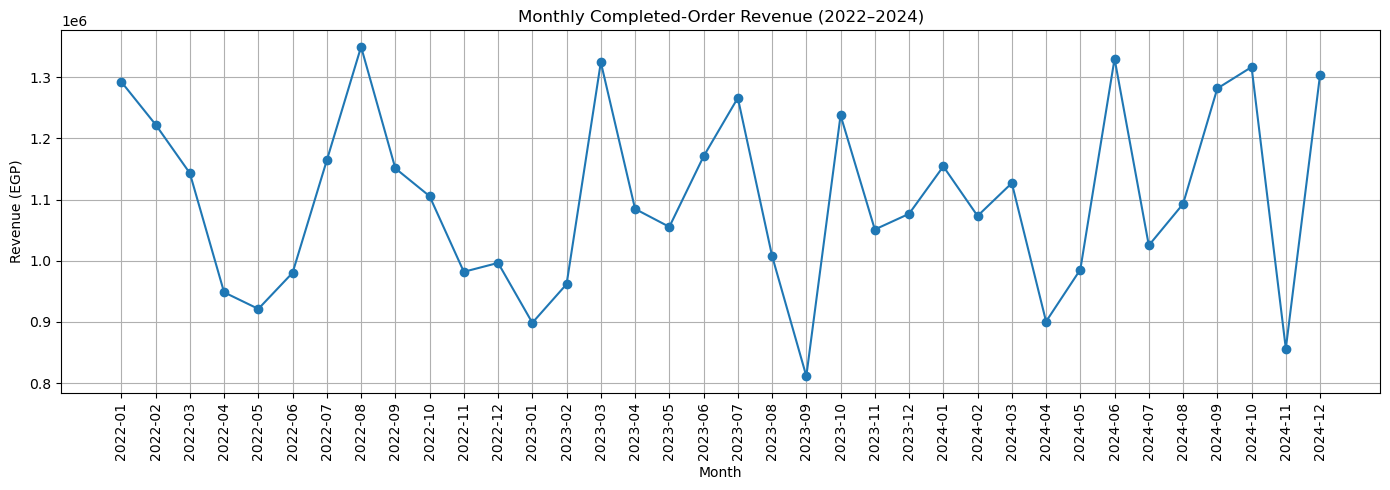

In [11]:
import matplotlib.pyplot as plt

monthly_sales["period"] = (
    monthly_sales["year"].astype(str) + "-" +
    monthly_sales["month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales["period"],
    monthly_sales["total_revenue"],
    marker="o"
)

plt.title("Monthly Completed-Order Revenue (2022–2024)")
plt.xlabel("Month")
plt.ylabel("Revenue (EGP)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

#### **What can we conclude?**

**A. Revenue fluctuates considerably between months.**

For example, September 2023 generated EGP 811,422, while October 2023 generated EGP 1,237,880.

That is a substantial difference between consecutive months.

**B. Order volume alone does not explain revenue.**

Consider June 2024 and December 2024:
- June: 310 orders generated EGP 1,330,310.
- December: 320 orders generated EGP 1,304,085.
December had more orders, but June generated more revenue.

This suggests differences in average order value.

**C. We cannot yet establish a consistent seasonal pattern.**

Although certain months appear stronger in particular years, we need to compare the same calendar months across all three years before concluding that a particular month is consistently strong or weak.

## Comparing Purchasing Activity Across Calendar Months

We want to investigate whether certain months consistently generate higher revenue.

In [12]:
# Aggregate monthly performance across all three years

seasonal_sales = (
    monthly_sales
    .groupby("month")
    .agg(
        average_monthly_orders=("total_orders", "mean"),
        average_monthly_revenue=("total_revenue", "mean")
    )
    .reset_index()
)

seasonal_sales.round(2)

,month,average_monthly_orders,average_monthly_revenue
0,1,304.67,1115114.83
1,2,268.00,1085889.17
2,3,290.33,1198240.83
3,4,285.33,977963.33
4,5,290.00,987439.33
5,6,284.33,1160432.33
6,7,285.33,1151891.50
7,8,300.67,1150191.50
8,9,291.33,1081390.50
9,10,306.00,1220041.00


#### **Key observations**

1. October is the strongest revenue-generating month.

    - It averages approximately EGP 1.22 million across the three years.

2. November and April are relatively weaker months.

    - November averages approximately EGP 963,186, while April averages EGP 977,963.

3. March also performs particularly well.

    - Its average revenue is approximately EGP 1.20 million, making it the second-highest month.

Order volume

- October also records the highest average monthly order volume (306 orders), followed by January (304.67).

    - This suggests that October's strong revenue is partly supported by higher purchasing activity.

But these are only descriptive observations, not proof of a recurring seasonal effect. We only have three observations for each calendar month.

## Examining Prouct Preferences

Here we are interested in what customers actually purchase 

Product preferences will help us understand customer behaviour and potentially identify useful customer-level features.

Let's examine revenue by product category using transaction data.

In [13]:
# Keep completed transactions only

completed_transactions = transaction[
    transaction["order_status"] == "Completed"
].copy()

# Analyse performance by product category

category_performance = (
    completed_transactions
    .groupby("category")
    .agg(
        total_quantity=("quantity", "sum"),
        total_revenue=("line_total_revenue", "sum"),
        unique_products=("product_id", "nunique"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

category_performance

,category,total_quantity,total_revenue,unique_products,unique_customers
1,Electronics,4086,30127855.0,37,1538
0,Clothing,33643,9524859.0,308,2886


#### **Key findings**

1. Electronics dominates revenue generation.

    * Electronics generate approximately 76% of the combined revenue from these two categories, despite accounting for only about 11% of the units sold.

        * This suggests that Electronics products have considerably higher selling prices.

2. Clothing has much wider customer reach.

    * A total of 2,886 customers purchased Clothing, compared with 1,538 for Electronics.

        * Clothing therefore appears to be the more widely purchased category.

3. Electronics has a smaller product portfolio.

    * Electronics has only 37 unique products, compared with 308 Clothing products.

        * Despite this smaller assortment, Electronics generates more than three times Clothing's revenue.

**Business implications**

Lotus Group appears to have two distinct product-category dynamics:
- Electronics: A major revenue driver, potentially requiring strong inventory management and high-value customer retention.
- Clothing: A broader customer acquisition and purchasing-frequency opportunity.

These are useful observations, although we want to the assumption that customers exclusively prefer one category. Many customers may purchase from both.

## Examining Product Subcategories

Here, we are interested in identifying which specific product segments drive revenue within each category.

In [14]:
subcategory_performance = (
    completed_transactions
    .groupby(["category", "subcategory"])
    .agg(
        total_quantity=("quantity", "sum"),
        total_revenue=("line_total_revenue", "sum"),
        unique_products=("product_id", "nunique"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

subcategory_performance

,category,subcategory,total_quantity,total_revenue,unique_products,unique_customers
10,Electronics,Mobile Phones,764,6493860.0,7,410
9,Electronics,Laptops,536,6258710.0,4,264
13,Electronics,TVs & Screens,434,5040465.0,4,246
8,Electronics,Gaming,341,4228845.0,3,177
7,Electronics,Audio & Wearables,824,3486320.0,8,455
14,Electronics,Tablets,306,2740950.0,3,176
3,Clothing,Outerwear,5671,2683496.5,52,1840
2,Clothing,Footwear,4835,2249984.0,44,1669
5,Clothing,Women Wear,8788,2051803.0,80,2260
1,Clothing,Bottoms,6419,1380559.5,60,1997


#### **Findings**

**Electronics dominates the highest revenue positions.**

- Mobile Phones and Laptops alone generate approximately EGP 12.75 million.

    - Reinforces our earlier finding that Electronics is the primary revenue-generating category.

**Clothing dominates customer reach.**

- Women Wear, for example, reaches 2,260 customers but generates EGP 2.05 million, considerably less than Mobile Phones.

    - Illustrates why revenue and customer reach should be examined separately.

**Business interpretation**

We can identify two important commercial patterns:
- Revenue drivers: Mobile Phones, Laptops, TVs & Screens and Gaming.
- Customer reach drivers: Women Wear, Tops, Bottoms, Outerwear and Footwear.

This could inform different marketing strategies. High-value electronics customers may benefit from retention campaigns, while clothing customers may present opportunities for cross-selling and increased purchase frequency.

**One important limitation**: customers can purchase from multiple subcategories, so the customer counts must not be added together to estimate the total customer population.

## Investigating Customer Category Preferences

This should be relevant to our predictive modelling objectives.

We want to understand whether customers concentrate their purchases in particular categories or purchase across both Electronics and Clothing.

Eventually, we may want to create customer-level features such as:
- Historical spending on Electronics.
- Historical spending on Clothing.
- Number of Electronics orders.
- Number of Clothing orders.
- Customer's preferred product category.

These could help our models identify differences in purchasing behaviour.

Important: When we eventually construct these features, we will calculate them using historical transactions only, up to each customer's observation date. We will not want future purchasing information to leak into the predictors.

In [15]:
# Calculate revenue by customer and product category

customer_category_spending = (
    completed_transactions
    .groupby(["customer_id", "category"])
    .agg(
        category_spending=("line_total_revenue", "sum"),
        category_orders=("order_id", "nunique"),
        category_quantity=("quantity", "sum")
    )
    .reset_index()
)

customer_category_spending.head(10)

,customer_id,category,category_spending,category_orders,category_quantity
0,CUS00001,Clothing,2899.0,4,12
1,CUS00001,Electronics,23290.0,4,7
2,CUS00002,Clothing,2722.0,5,10
3,CUS00002,Electronics,800.0,1,1
4,CUS00003,Clothing,199.5,1,1
5,CUS00004,Clothing,4823.5,6,22
6,CUS00004,Electronics,22590.0,2,3
7,CUS00005,Clothing,1340.0,1,4
8,CUS00006,Clothing,4429.0,4,20
9,CUS00006,Electronics,25600.0,1,2


##### **What we can learn from this**

Customers demonstrate different purchasing preferences. Some spend across both categories, while others purchase from only one.

This is useful because category-level purchasing behaviour may help our models distinguish between customers with different spending patterns.

For example:
- A customer who frequently purchases Electronics may have a different spending profile from one who mainly purchases Clothing.
- A customer who purchases across both categories may demonstrate broader purchasing behaviour.
- Category spending and order frequency could help predict future purchasing activity.

**Important distinction**: these are only historical descriptive results, not yet modelling features. When we build the features, we must calculate them using transactions available before each observation date.

## Examining Category Preference Across Customers

We want to establish how many customers purchase from one category versus both categories.

In [16]:
# Count the number of product categories purchased by each customer

customer_category_count = (
    customer_category_spending
    .groupby("customer_id")
    .agg(
        categories_purchased=("category", "nunique")
    )
    .reset_index()
)

# Summarise customers by number of categories purchased

customer_category_count["categories_purchased"].value_counts().sort_index()

categories_purchased
1    1386
2    1519
Name: count, dtype: int64

**Interpretation**

Three observations stand out:
1. Cross-category purchasing is common. 
    - Slightly more than half of purchasing customers bought both Clothing and Electronics.
2. Single-category purchasing is also significant. 
    - Approximately 48% purchased from only one category, suggesting opportunities for cross-selling.
3. Category preference could be useful for customer targeting. 
    - Lotus Group could use historical category spending to identify customers who may respond to complementary product recommendations.

This completes our examination of customer category preferences.

## Customer Retention and Purchasing Recency.

We want to understand how recently customers purchased, because recency is particularly relevant when predicting whether someone will purchase again within the next 90 days.

We'll start by calculating the most recent completed purchase date in the dataset

In [17]:
completed_orders["order_date"].max()

Timestamp('2024-12-31 00:00:00')

This establishes the end of our historical observation period. 

We cannot use 31 December 2024 as a modelling observation date if we want to predict purchases over the following 90 days: the dataset contains no transactions beyond that date to establish the actual outcomes.

To examine customer purchasing recency **let's calculate each customer's most recent completed purchase**

Recency measures how long it has been since a customer last made a completed purchase.

For example:
- 5 days: very recent purchasing activity.
- 45 days: the customer has not purchased for approximately six weeks.
- 180 days: the customer has been inactive for approximately six months.

This is potentially an important predictor of future purchasing behaviour.

In [18]:
# Find each customer's most recent completed purchase date

customer_recency = (
    completed_orders
    .groupby("customer_id")
    .agg(
        last_purchase_date=("order_date", "max")
    )
    .reset_index()
)

# Use the dataset's final date as the reference date
reference_date = completed_orders["order_date"].max()

# Calculate days since the last purchase
customer_recency["recency_days"] = (
    reference_date - customer_recency["last_purchase_date"]
).dt.days

customer_recency.head(10)

,customer_id,last_purchase_date,recency_days
0,CUS00001,2024-11-10,51
1,CUS00002,2024-10-06,86
2,CUS00003,2023-04-06,635
3,CUS00004,2024-06-02,212
4,CUS00005,2024-06-19,195
5,CUS00006,2024-04-22,253
6,CUS00007,2023-07-27,523
7,CUS00008,2024-11-24,37
8,CUS00009,2024-07-01,183
9,CUS00010,2023-12-11,386


The sample illustrates substantial differences in customer recency:

- CUS00008: Last purchased 37 days before the reference date.
- CUS00001: Last purchased 51 days before the reference date.
- CUS00003: Last purchased 635 days before the reference date.
- CUS00007: Last purchased 523 days before the reference date.

This suggests that some customers have purchased relatively recently, while others have been inactive for extended periods.

**Examine the recency distribution**

In [19]:
customer_recency["recency_days"].describe()

count    2905.000000
mean      273.304991
std       243.522292
min         0.000000
25%        84.000000
50%       201.000000
75%       399.000000
max      1093.000000
Name: recency_days, dtype: float64

In [20]:
# Group customers into recency bands

recency_summary = (
    customer_recency
    .assign(
        recency_group=pd.cut(
            customer_recency["recency_days"],
            bins=[-1, 30, 90, 180, 365, float("inf")],
            labels=[
                "0–30 days",
                "31–90 days",
                "91–180 days",
                "181–365 days",
                "Over 365 days"
            ]
        )
    )
    .groupby("recency_group", observed=False)
    .agg(
        customer_count=("customer_id", "nunique")
    )
    .reset_index()
)

recency_summary["percentage"] = (
    recency_summary["customer_count"] /
    recency_summary["customer_count"].sum() * 100
)

recency_summary

,recency_group,customer_count,percentage
0,0–30 days,301,10.361446
1,31–90 days,487,16.764200
2,91–180 days,552,19.001721
3,181–365 days,758,26.092943
4,Over 365 days,807,27.779690


The average recency of 273 days is higher than the median of 201 days. This suggests that a considerable number of customers have relatively long periods of inactivity, pulling the average upwards.

**Key observations**:

1. 788 customers (27.13%) made their last completed purchase within the preceding 90 days.
2. 1,359 customers (46.78%) had not made a completed purchase in over 180 days.
3. 807 customers (27.78%) had gone more than a year without a completed purchase.

These figures suggest that customer inactivity deserves attention in Lotus Group's retention strategy.

One important qualification: these are historical recency measurements, not confirmed churn classifications. A customer who has not purchased for 365 days may still return.

Also, we have to keep in mind that this analysis covers 2,905 customers with completed purchases, not the entire registered customer base of 3,000.